Shape: (2823, 18)
   ORDERNUMBER  QUANTITYORDERED  PRICEEACH  ORDERLINENUMBER    SALES  \
0        10107               30      95.70                2  2871.00   
1        10121               34      81.35                5  2765.90   
2        10134               41      94.74                2  3884.34   
3        10145               45      83.26                6  3746.70   
4        10159               49     100.00               14  5205.27   

  ORDERDATE   STATUS  QTR_ID  MONTH_ID  YEAR_ID  PRODUCTLINE  MSRP  \
0  02/24/03  Shipped       1         2     2003  Motorcycles    95   
1  05/07/03  Shipped       2         5     2003  Motorcycles    95   
2  07/01/03  Shipped       3         7     2003  Motorcycles    95   
3  08/25/03  Shipped       3         8     2003  Motorcycles    95   
4  10/10/03  Shipped       4        10     2003  Motorcycles    95   

  PRODUCTCODE              CUSTOMERNAME           CITY COUNTRY TERRITORY  \
0    S10_1678         Land of Toys Inc.            N

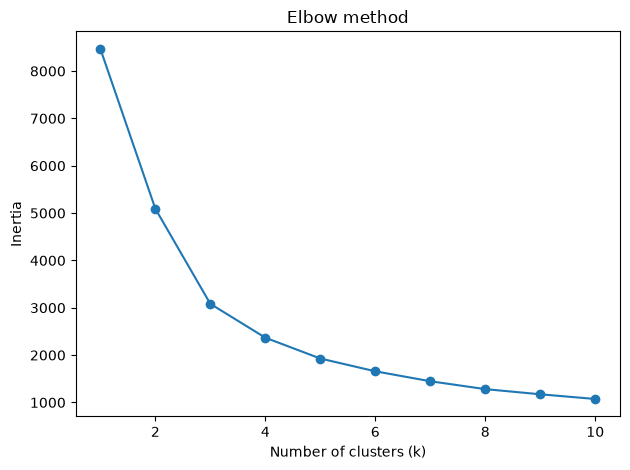

k = 2 silhouette = 0.359
k = 3 silhouette = 0.412
k = 4 silhouette = 0.422
k = 5 silhouette = 0.374
k = 6 silhouette = 0.379
k = 7 silhouette = 0.349

Customers per cluster:
 Cluster
2    1035
1     907
0     881
Name: count, dtype: int64

Average values per cluster:
          QUANTITYORDERED  PRICEEACH        SALES
Cluster                                         
0              35.125993  57.130216  2009.829955
1              43.847850  96.637795  5584.007299
2              27.392271  94.865575  3089.153662


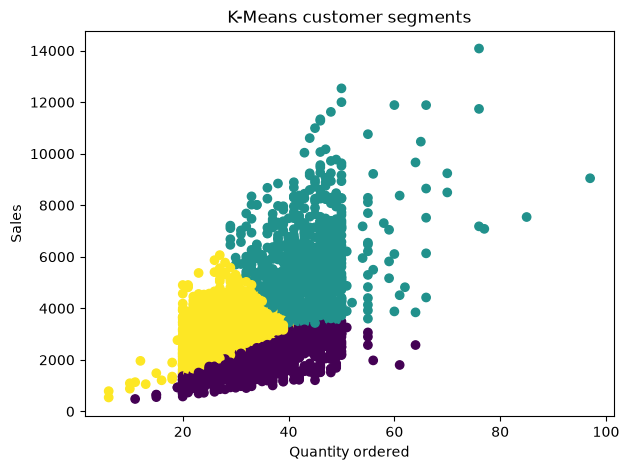

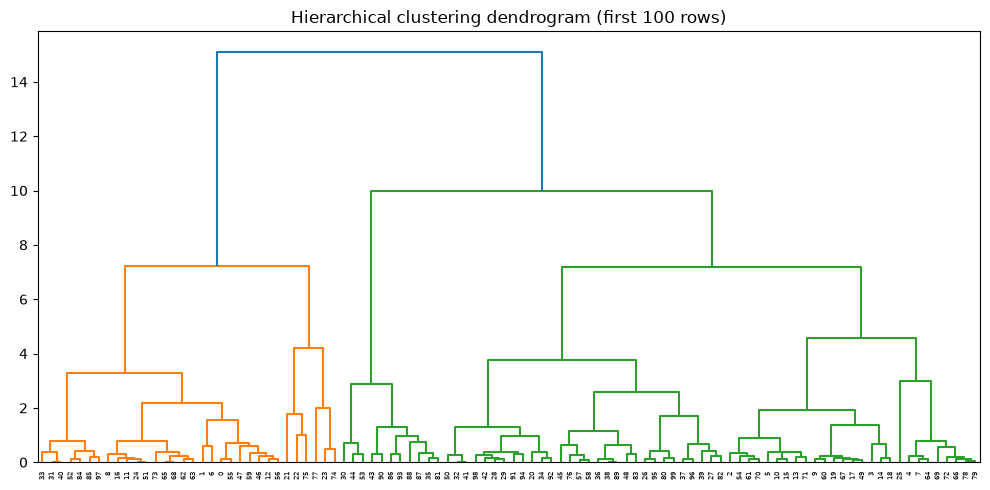


Hierarchical cluster counts:
 HierCluster
2    1124
0    1014
1     685
Name: count, dtype: int64


In [1]:
"""B5: Customer segmentation using K-Means and hierarchical clustering."""
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import dendrogram, linkage

DATA_URL = "https://raw.githubusercontent.com/echu-vb/manufacturing-sales-analysis/d5d9296d41f1e43d0335b7c0f3dbcd87e88fe2fc/sales_data_sample.csv"
df = pd.read_csv(DATA_URL, encoding="latin1")

print("Shape:", df.shape)
print(df.head())
print("Missing values:\n", df.isnull().sum())

features = ["QUANTITYORDERED", "PRICEEACH", "SALES"]
X = df[features].dropna()
print(X.describe())

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Elbow method: compare within-cluster sum of squares.
inertia = []
max_k = min(10, len(X) - 1)
for k in range(1, max_k + 1):
    model = KMeans(n_clusters=k, n_init=10, random_state=42)
    model.fit(X_scaled)
    inertia.append(model.inertia_)
    print("k =", k, "inertia =", round(model.inertia_, 2))

plt.plot(range(1, max_k + 1), inertia, marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow method")
plt.tight_layout()
plt.show()

# Silhouette score is defined only when there are 2..n-1 clusters.
for k in range(2, min(8, len(X))):
    labels = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(X_scaled)
    print("k =", k, "silhouette =", round(silhouette_score(X_scaled, labels), 3))

# Select K after examining the elbow plot; 3 is the demonstration default.
k = 3
if k >= len(X):
    raise ValueError("Choose a cluster count smaller than the number of rows.")

kmeans = KMeans(n_clusters=k, n_init=10, random_state=42)
clusters = kmeans.fit_predict(X_scaled)
result = df.loc[X.index].copy()
result["Cluster"] = clusters

print("\nCustomers per cluster:\n", result["Cluster"].value_counts())
print("\nAverage values per cluster:\n", result.groupby("Cluster")[features].mean())

plt.scatter(result["QUANTITYORDERED"], result["SALES"], c=result["Cluster"])
plt.xlabel("Quantity ordered")
plt.ylabel("Sales")
plt.title("K-Means customer segments")
plt.tight_layout()
plt.show()

# Dendrogram is displayed for a sample to keep plotting manageable.
sample_size = min(100, len(X_scaled))
plt.figure(figsize=(10, 5))
dendrogram(linkage(X_scaled[:sample_size], method="ward"))
plt.title(f"Hierarchical clustering dendrogram (first {sample_size} rows)")
plt.tight_layout()
plt.show()

hierarchical = AgglomerativeClustering(n_clusters=k, linkage="ward")
result["HierCluster"] = hierarchical.fit_predict(X_scaled)
print("\nHierarchical cluster counts:\n", result["HierCluster"].value_counts())
